Importing the dataset

In [89]:
from google.colab import drive
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
# Mount Google Drive
drive.mount('/content/drive')

# Load dataset (update the path to where your file is in Drive)
file_path = "/content/drive/MyDrive/CSE422 Project/Bank Marketing.csv"
dataset = pd.read_csv(file_path)
dataset


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


Features

In [90]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

Numerical Features

In [91]:

##Selecting numerical features
numerical_data = dataset.select_dtypes(include='number')

#append the features of numerical_data to list
numerical_features=numerical_data.columns.tolist()

print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 10 numerical features: 

['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


Categorical Features

In [92]:
#Selecting categoricalfeatures
categorical_data=dataset.select_dtypes(include= 'object')

#append the features of categorical_data to list
categorical_features=categorical_data.columns.tolist()

print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 11 categorical features: 

['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


Data points

In [93]:
print("Shape:", dataset.shape, "| rows:", dataset.shape[0], "| columns:", dataset.shape[1])


Shape: (41188, 21) | rows: 41188 | columns: 21


Correlation Analysis

In [94]:
#Correlation matrix of whole dataset
correlation_matrix = numerical_data.corr()
correlation_matrix


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
age,1.000000,-0.000866,0.004594,-0.034369,0.024365,-0.000371,0.000857,0.129372,0.010767,-0.017725
duration,-0.000866,1.000000,-0.071699,-0.047577,0.020640,-0.027968,0.005312,-0.008173,-0.032897,-0.044703
campaign,0.004594,-0.071699,1.000000,0.052584,-0.079141,0.150754,0.127836,-0.013733,0.135133,0.144095
pdays,-0.034369,-0.047577,0.052584,1.000000,-0.587514,0.271004,0.078889,-0.091342,0.296899,0.372605
previous,0.024365,0.020640,-0.079141,-0.587514,1.000000,-0.420489,-0.203130,-0.050936,-0.454494,-0.501333
emp.var.rate,-0.000371,-0.027968,0.150754,0.271004,-0.420489,1.000000,0.775334,0.196041,0.972245,0.906970
cons.price.idx,0.000857,0.005312,0.127836,0.078889,-0.203130,0.775334,1.000000,0.058986,0.688230,0.522034
cons.conf.idx,0.129372,-0.008173,-0.013733,-0.091342,-0.050936,0.196041,0.058986,1.000000,0.277686,0.100513
euribor3m,0.010767,-0.032897,0.135133,0.296899,-0.454494,0.972245,0.688230,0.277686,1.000000,0.945154
nr.employed,-0.017725,-0.044703,0.144095,0.372605,-0.501333,0.906970,0.522034,0.100513,0.945154,1.000000


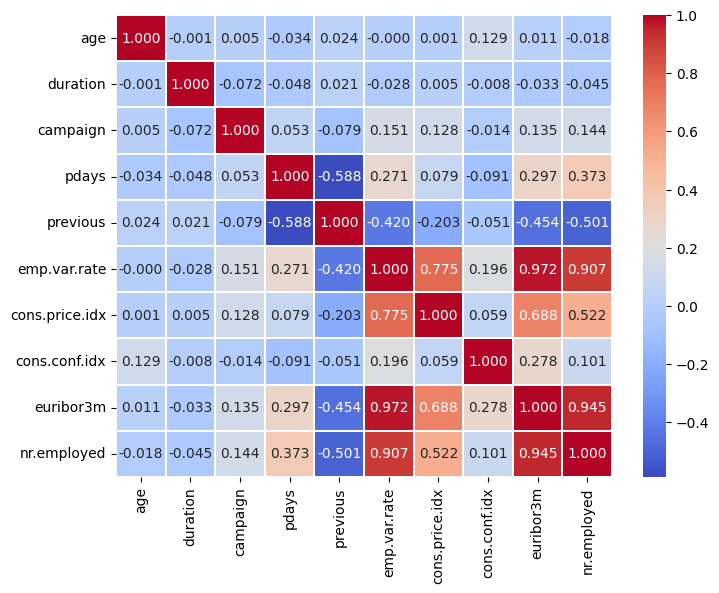

In [95]:
# Plotting the heatmap for correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.show()

Encoding of categorical features and correlation analysis of all features

In [96]:
from sklearn.preprocessing import LabelEncoder
dataset_encoded = dataset.copy()
encoder = LabelEncoder()

for col in dataset_encoded.select_dtypes(include=['object']).columns:
    dataset_encoded[col] = encoder.fit_transform(dataset_encoded[col])

# Correlation matrix
corr = dataset_encoded.corr()
corr

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
age,1.000000,0.001250,-0.389753,-0.117892,0.164965,-0.001603,-0.007368,0.007021,-0.024877,-0.017572,...,0.004594,-0.034369,0.024365,0.019750,-0.000371,0.000857,0.129372,0.010767,-0.017725,0.030399
job,0.001250,1.000000,0.027897,0.134121,-0.028277,0.006962,-0.010209,-0.025132,-0.033213,-0.000844,...,-0.006923,-0.028468,0.020965,0.011504,-0.008271,-0.016017,0.052760,-0.007880,-0.019574,0.025122
marital,-0.389753,0.027897,1.000000,0.109220,-0.079450,0.010467,0.005788,-0.054501,-0.007629,0.002202,...,-0.007240,-0.037942,0.038689,0.001912,-0.084210,-0.057477,-0.033783,-0.091939,-0.086199,0.046203
education,-0.117892,0.134121,0.109220,1.000000,-0.186859,0.016825,0.006384,-0.105726,-0.082684,-0.017986,...,0.000371,-0.046626,0.038831,0.017009,-0.043778,-0.081607,0.078799,-0.036380,-0.041492,0.057799
default,0.164965,-0.028277,-0.079450,-0.186859,1.000000,-0.015815,-0.003782,0.135238,-0.015830,-0.008701,...,0.032825,0.080062,-0.102416,0.023417,0.203263,0.168073,0.026522,0.195336,0.189845,-0.099352
housing,-0.001603,0.006962,0.010467,0.016825,-0.015815,1.000000,0.044296,-0.082186,-0.018141,0.003339,...,-0.011010,-0.010551,0.021314,-0.011783,-0.060196,-0.080504,-0.033845,-0.059277,-0.045862,0.011552
loan,-0.007368,-0.010209,0.005788,0.006384,-0.003782,0.044296,1.000000,-0.008556,-0.005705,-0.009344,...,0.005166,0.000345,-0.001327,-0.001511,0.001849,-0.002430,-0.012025,0.000125,0.003903,-0.004909
contact,0.007021,-0.025132,-0.054501,-0.105726,0.135238,-0.082186,-0.008556,1.000000,0.276565,-0.009575,...,0.077368,0.117970,-0.212848,0.118744,0.393584,0.591474,0.251614,0.399773,0.269155,-0.144773
month,-0.024877,-0.033213,-0.007629,-0.082684,-0.015830,-0.018141,-0.005705,0.276565,1.000000,0.027677,...,-0.062059,-0.047891,0.103157,-0.065012,-0.178782,-0.004239,0.009652,-0.117264,-0.221425,-0.006065
day_of_week,-0.017572,-0.000844,0.002202,-0.017986,-0.008701,0.003339,-0.009344,-0.009575,0.027677,1.000000,...,-0.038288,-0.009531,-0.004102,0.018732,0.033245,0.005644,0.041465,0.039043,0.028380,0.015967


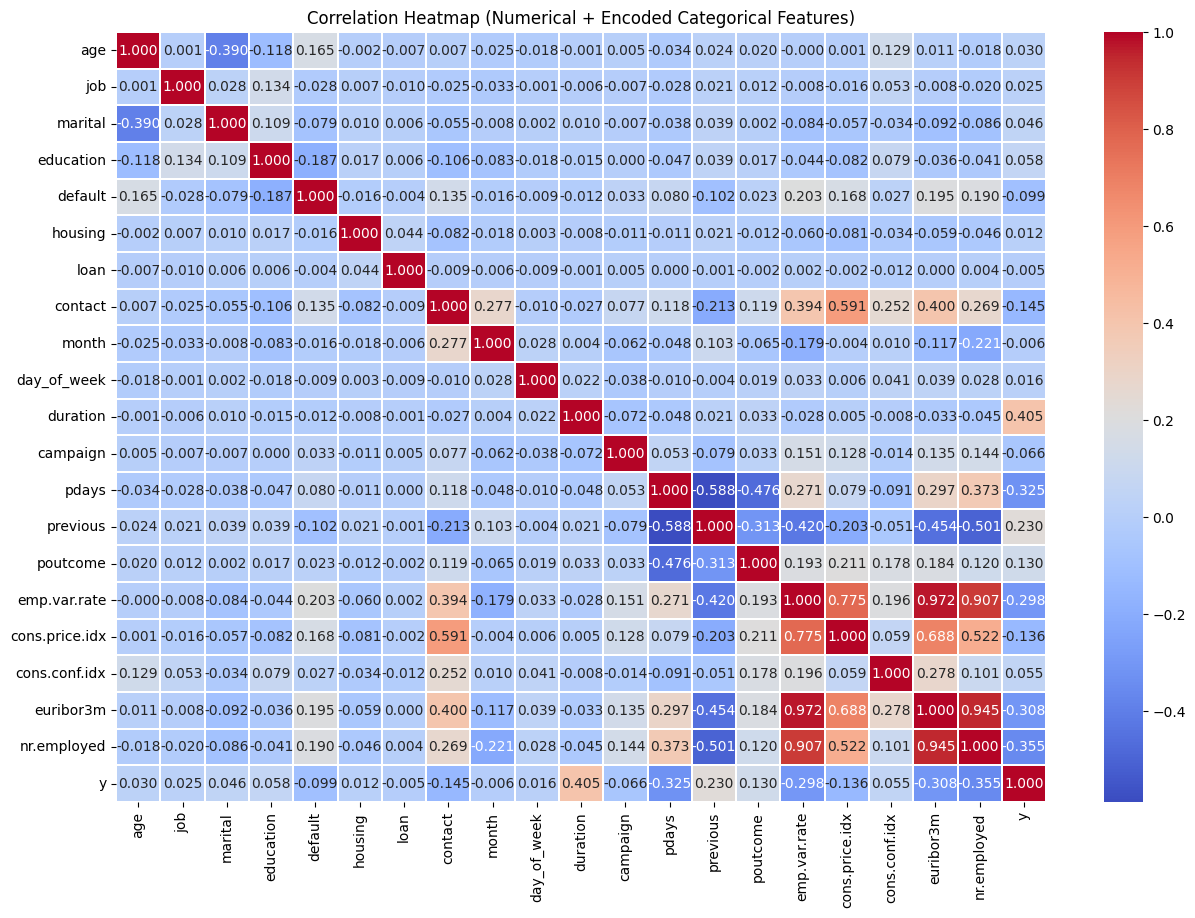

In [97]:
plt.figure(figsize=(15,10))
sns.heatmap(corr, cmap="coolwarm", annot=True, fmt='.3f', linewidths=0.3)
plt.title("Correlation Heatmap (Numerical + Encoded Categorical Features)")
plt.show()

Correlation plot between features and target

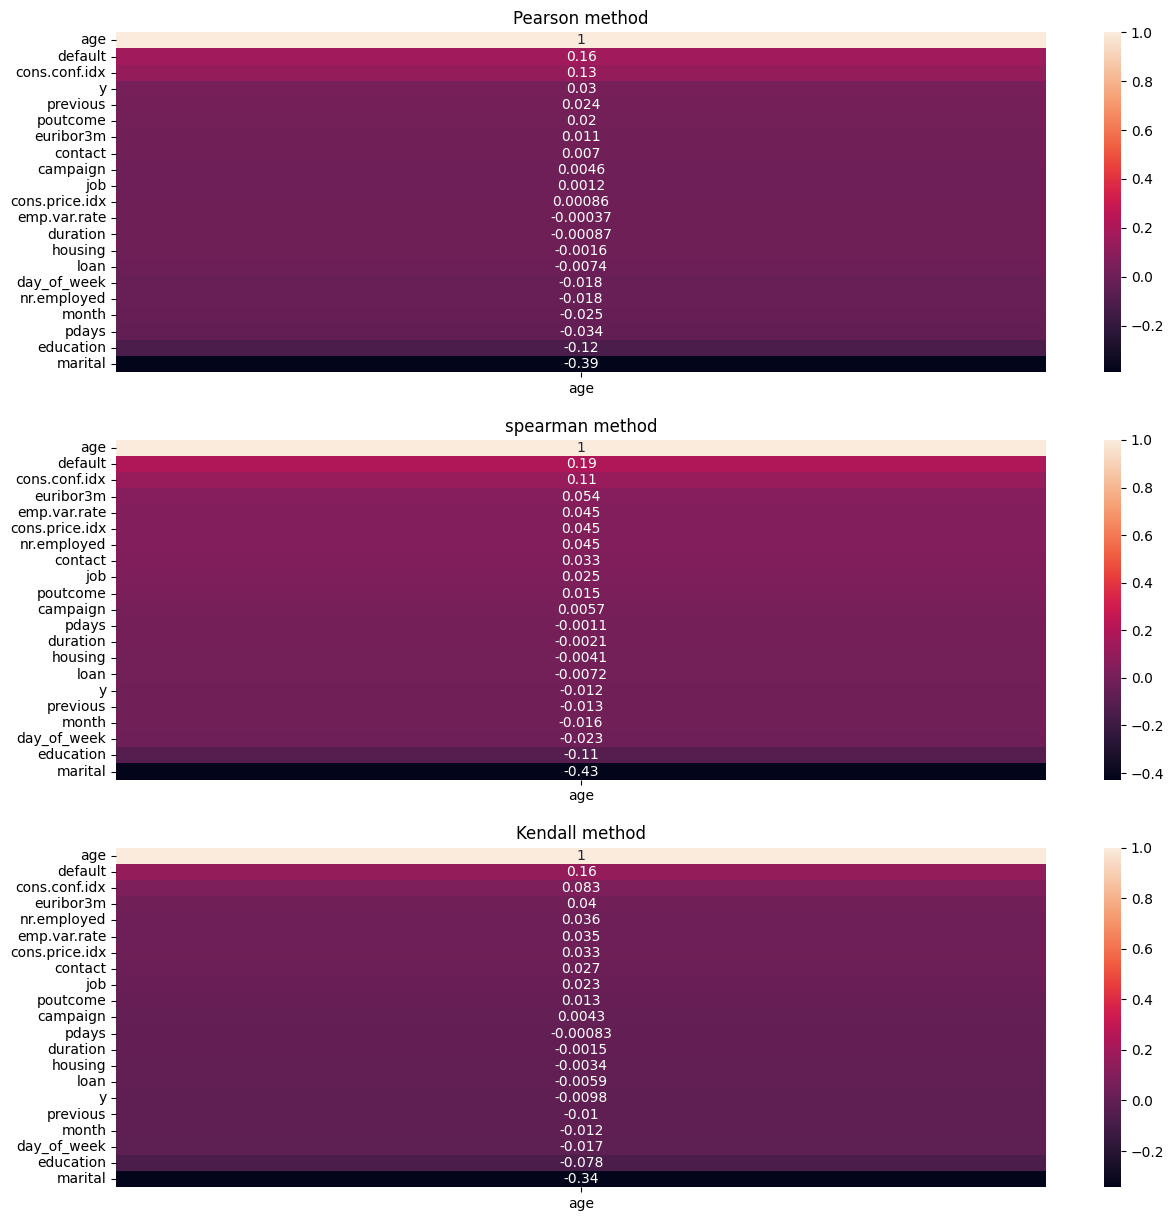

In [98]:
fig, ax = plt.subplots(3,1, figsize=(15, 15))
## Correlation coefficient using different methods
corr1 = dataset_encoded.corr('pearson')[['age']].sort_values(by='age', ascending=False)
corr2 = dataset_encoded.corr('spearman')[['age']].sort_values(by='age', ascending=False)
corr3 = dataset_encoded.corr('kendall')[['age']].sort_values(by='age', ascending=False)

#setting titles for each plot
ax[0].set_title('Pearson method')
ax[1].set_title('spearman method')
ax[2].set_title('Kendall method')

## Generating heatmaps of each methods
sns.heatmap(corr1, ax=ax[0], annot=True)
sns.heatmap(corr2, ax=ax[1], annot=True)
sns.heatmap(corr3, ax=ax[2], annot=True)

plt.show()

No of unique values in each  feature

In [99]:
unique_counts=dataset_encoded.nunique()
print(unique_counts)

age                 78
job                 12
marital              4
education            8
default              3
housing              3
loan                 3
contact              2
month               10
day_of_week          5
duration          1544
campaign            42
pdays               27
previous             8
poutcome             3
emp.var.rate        10
cons.price.idx      26
cons.conf.idx       26
euribor3m          316
nr.employed         11
y                    2
dtype: int64


Barplot of unique value counts in age

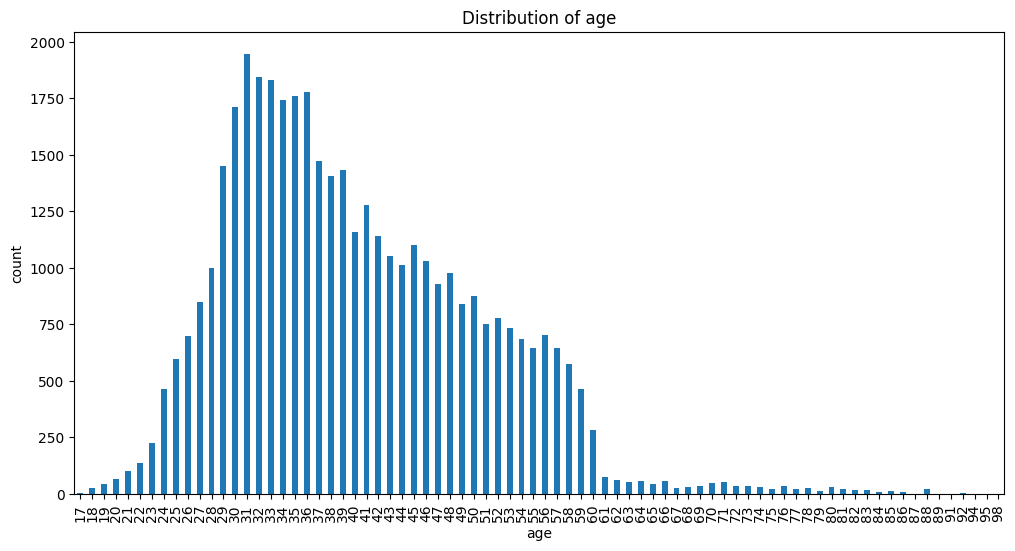

In [100]:
plt.figure(figsize=(12,6))
plt.title(f'Distribution of age')
numerical_data['age'].value_counts().sort_index().plot(kind='bar', rot=90, xlabel="age",ylabel='count')
# plt.xticks(ticks=range(0, len(ax.get_xticks()), 5),
#            labels=[lab.get_text() for i, lab in enumerate(ax.get_xticklabels()) if i % 5 == 0])
plt.show()

Summary satistics of Numerical Features

In [101]:
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


Summary satistics of Categorical features

In [102]:
categorical_data.describe().T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


Skew in features

In [103]:
dataset_encoded.skew()

,0
age,0.784697
job,0.450818
marital,-0.057136
education,-0.235148
default,1.435659
housing,-0.143783
loan,1.816348
contact,0.559720
month,-0.309755
day_of_week,0.008172


Histograms and Box Plot

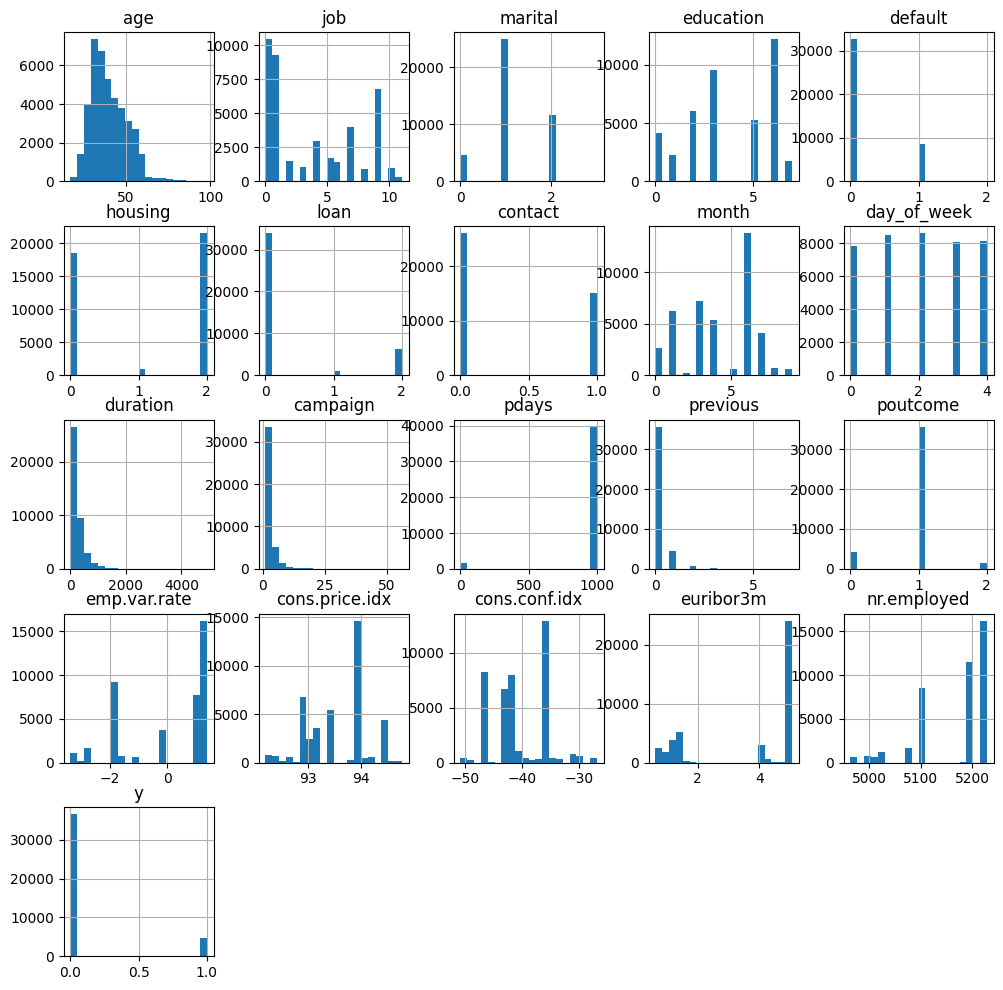

In [104]:
dataset_encoded.hist(figsize=(12,12),bins=20)
plt.show()

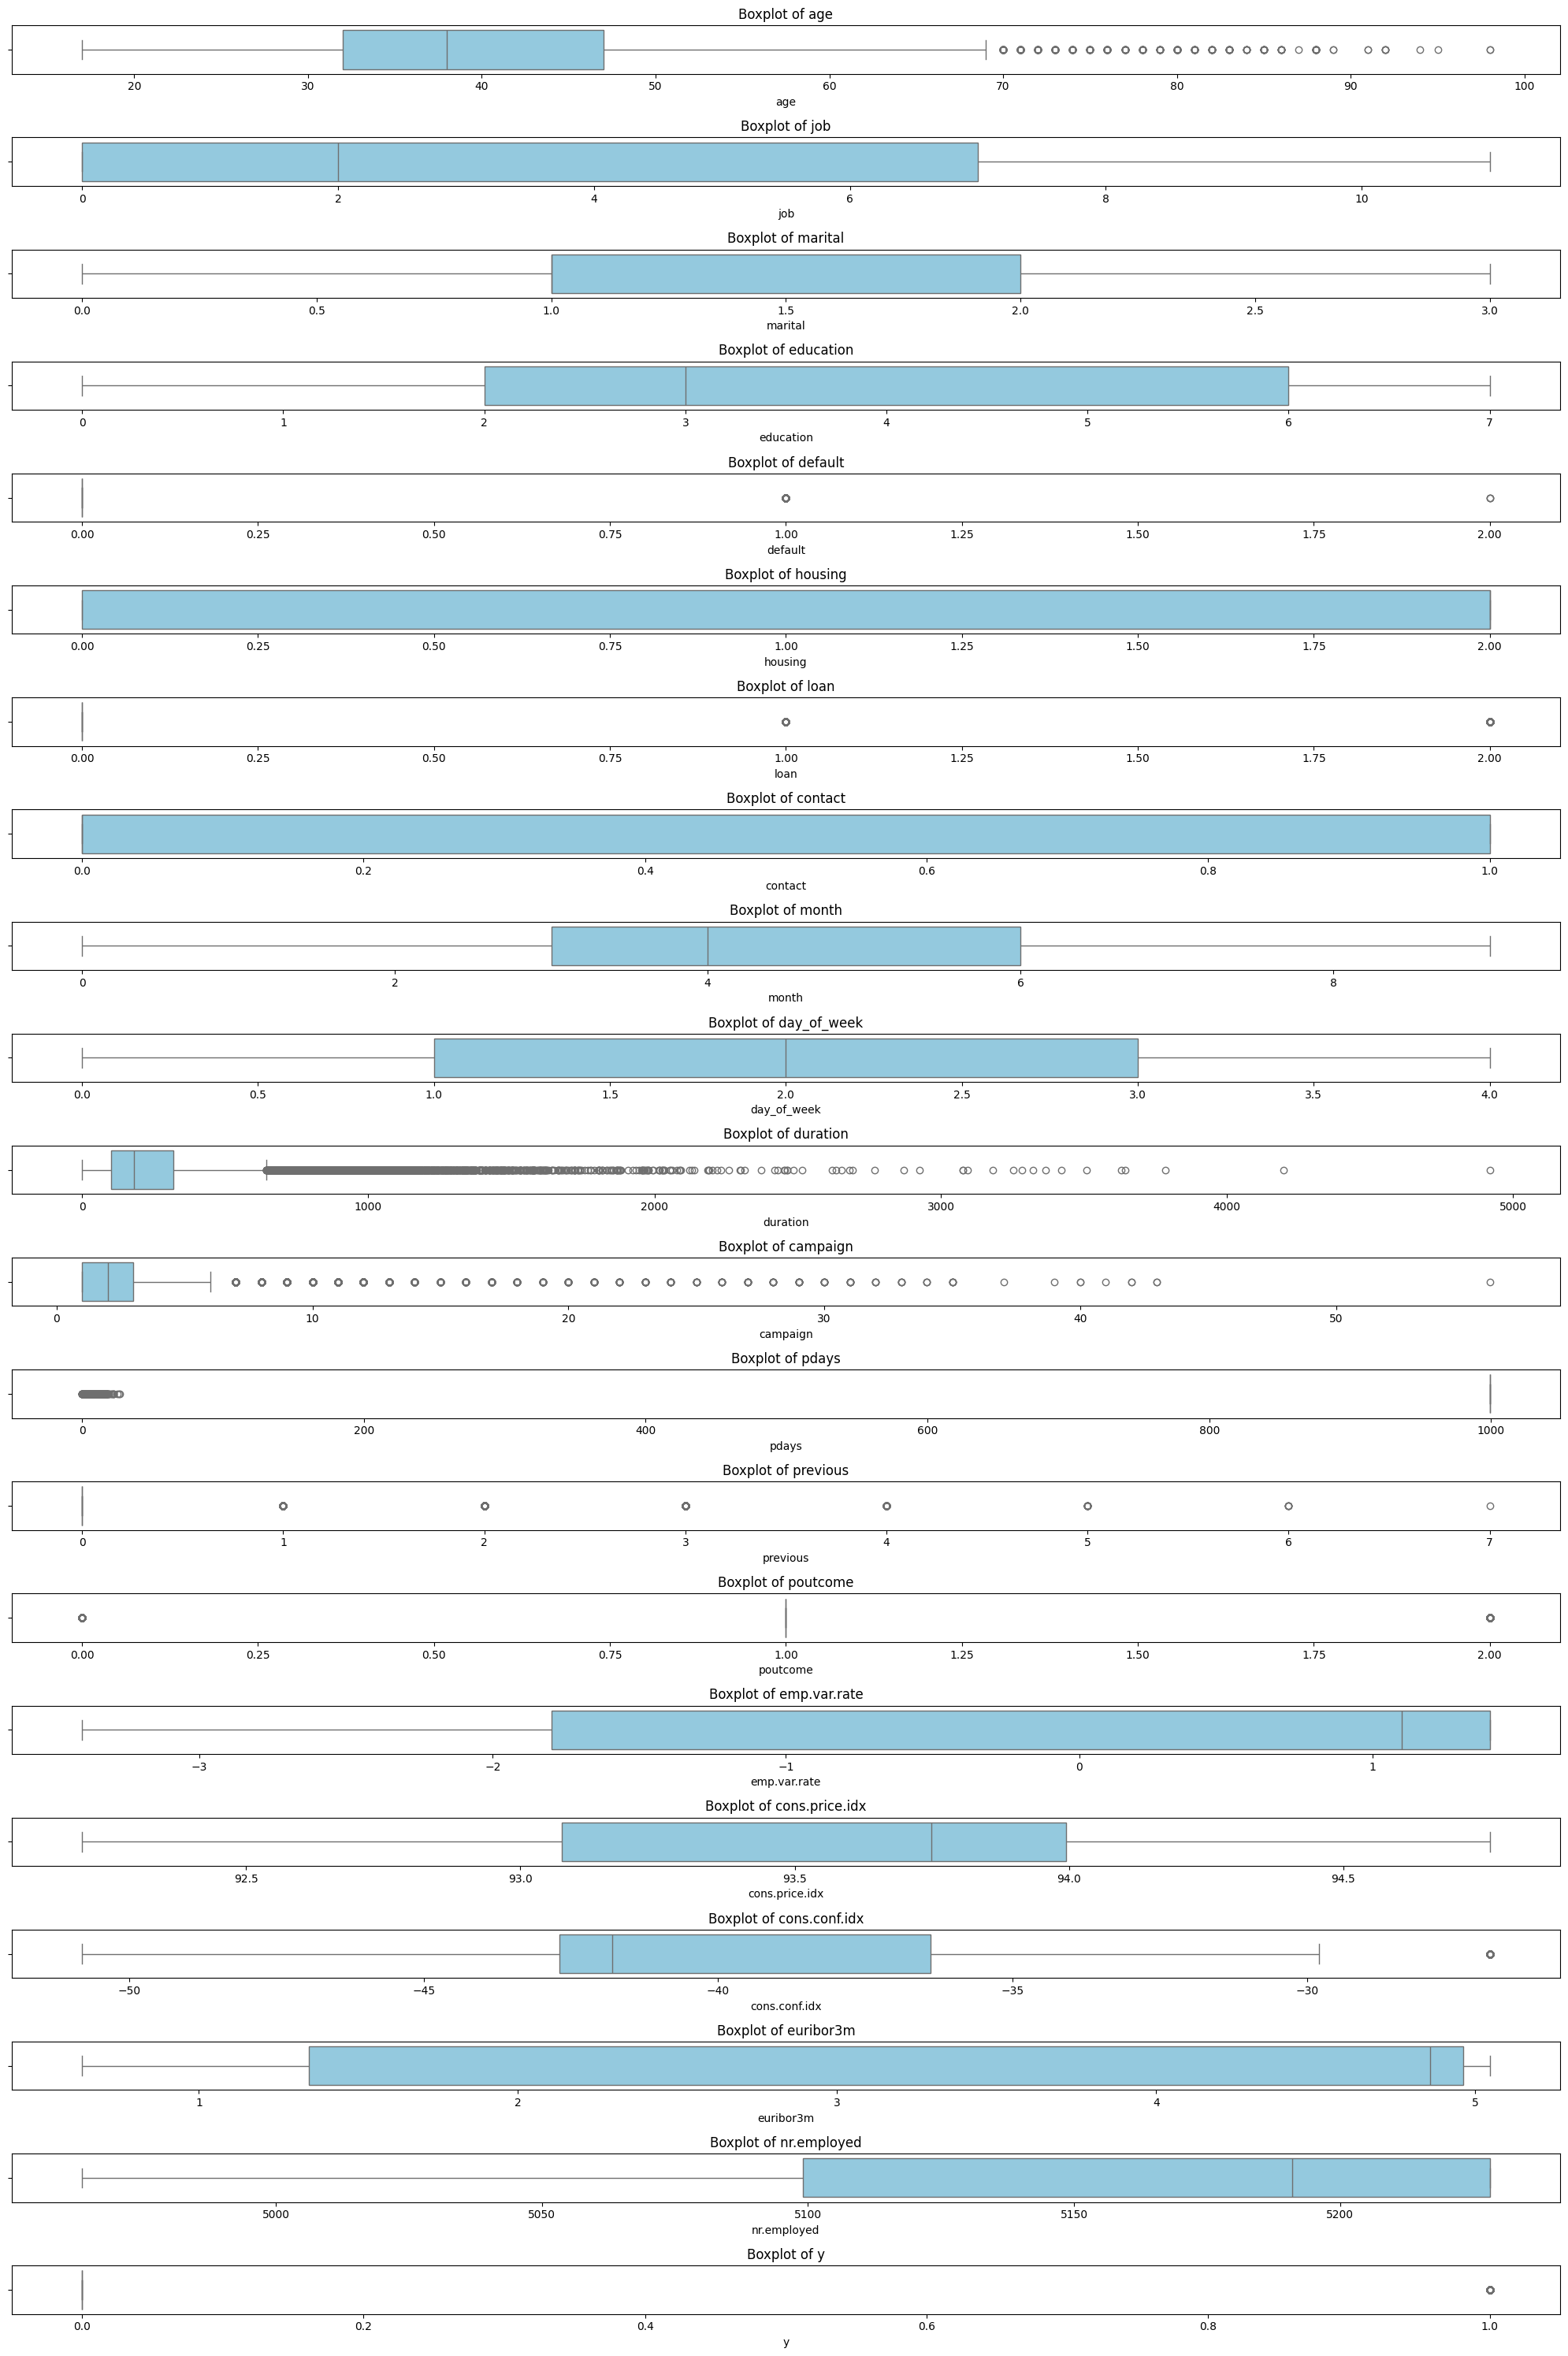

In [105]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for boxplot analysis
numeric_cols = dataset_encoded.select_dtypes(include=['int64', 'float64']).columns

# Set up the figure
plt.figure(figsize=(20, 30))

# Plot boxplots for each numerical feature including the target variable 'OUTCOME'
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=dataset_encoded[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()


Density plots of features

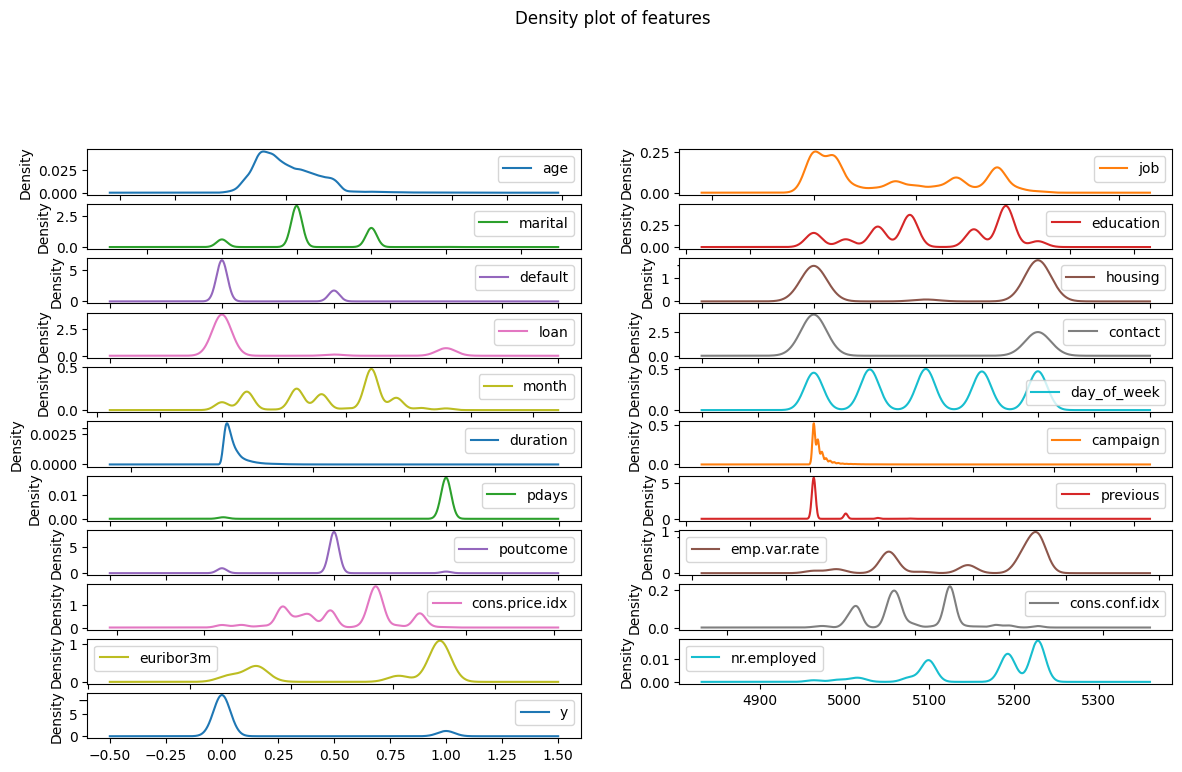

In [106]:
dataset_encoded.plot(kind='density',figsize=(14,14),subplots=True,layout=(20,2),title="Density plot of features",sharex=False)
plt.show()

Data Preprocessing

column dropping

In [107]:
final_dataset=dataset.copy()
final_dataset = final_dataset.drop(['y', 'duration', 'pdays', 'euribor3m', 'nr.employed', 'campaign', 'contact', 'month', 'day_of_week', 'poutcome'], axis = 1) #10 columns dropped
final_dataset.shape

(41188, 11)

Null/missing values

In [108]:
final_dataset.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
previous,0
emp.var.rate,0
cons.price.idx,0


Encoding

In [109]:
print(final_dataset['default'].unique())
print(final_dataset['housing'].unique())
print(final_dataset['loan'].unique())

['no' 'unknown' 'yes']
['no' 'yes' 'unknown']
['no' 'yes' 'unknown']


In [110]:
from sklearn.preprocessing import LabelEncoder
dataset_encoded = dataset.copy()
encoder = LabelEncoder()

for col in ['default','housing', 'loan']:
    final_dataset[col] = encoder.fit_transform(final_dataset[col])
print(final_dataset[['default','housing', 'loan']].head())

   default  housing  loan
0        0        0     0
1        1        0     0
2        0        2     0
3        0        0     0
4        0        0     2


In [111]:
print(final_dataset['job'].unique())
print(final_dataset['marital'].unique())
print(final_dataset['education'].unique())

['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student']
['married' 'single' 'divorced' 'unknown']
['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'unknown' 'university.degree' 'illiterate']


In [112]:
from sklearn.preprocessing import OneHotEncoder


categorical_columns = final_dataset.select_dtypes(include=['object']).columns.tolist()
encoder = OneHotEncoder(sparse_output=False)

one_hot_encoded = encoder.fit_transform(final_dataset[categorical_columns])

one_hot_df = pd.DataFrame(one_hot_encoded, columns=encoder.get_feature_names_out(categorical_columns))

processed_dataset = pd.concat([final_dataset, one_hot_df], axis=1)

processed_dataset= processed_dataset.drop(categorical_columns, axis=1)
print(f"Encoded Employee data : \n{processed_dataset}")

Encoded Employee data : 
       age  default  housing  loan  previous  emp.var.rate  cons.price.idx  \
0       56        0        0     0         0           1.1          93.994   
1       57        1        0     0         0           1.1          93.994   
2       37        0        2     0         0           1.1          93.994   
3       40        0        0     0         0           1.1          93.994   
4       56        0        0     2         0           1.1          93.994   
...    ...      ...      ...   ...       ...           ...             ...   
41183   73        0        2     0         0          -1.1          94.767   
41184   46        0        0     0         0          -1.1          94.767   
41185   56        0        2     0         0          -1.1          94.767   
41186   44        0        0     0         0          -1.1          94.767   
41187   74        0        2     0         1          -1.1          94.767   

       cons.conf.idx  job_admin.  job_

applying log1p on previous

In [113]:
# Suppose your dataframe is called df
print("Skewness before:", processed_dataset['previous'].skew())
processed_dataset['previous_log'] = np.log1p(processed_dataset['previous'])

# Drop the old 'previous' column if you don’t need it anymore
processed_dataset = processed_dataset.drop('previous', axis=1)

# Check skewness after transformation
print("Skewness after:", processed_dataset['previous_log'].skew())
processed_dataset

Skewness before: 3.8320422428611836
Skewness after: 2.587040192505977


,age,default,housing,loan,emp.var.rate,cons.price.idx,cons.conf.idx,job_admin.,job_blue-collar,job_entrepreneur,...,marital_unknown,education_basic.4y,education_basic.6y,education_basic.9y,education_high.school,education_illiterate,education_professional.course,education_university.degree,education_unknown,previous_log
0,56,0,0,0,1.1,93.994,-36.4,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
1,57,1,0,0,1.1,93.994,-36.4,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.000000
2,37,0,2,0,1.1,93.994,-36.4,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.000000
3,40,0,0,0,1.1,93.994,-36.4,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
4,56,0,0,2,1.1,93.994,-36.4,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,0,2,0,-1.1,94.767,-50.8,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.000000
41184,46,0,0,0,-1.1,94.767,-50.8,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.000000
41185,56,0,2,0,-1.1,94.767,-50.8,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.000000
41186,44,0,0,0,-1.1,94.767,-50.8,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.000000


Robust scaling

In [114]:
from sklearn.preprocessing import RobustScaler
numeric_features = ['previous_log', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx']

# Initialize RobustScaler
scaler = RobustScaler()

# Fit and transform
processed_dataset[numeric_features] = scaler.fit_transform(processed_dataset[numeric_features])

# Check result
print(processed_dataset[numeric_features].head())

   previous_log  emp.var.rate  cons.price.idx  cons.conf.idx
0           0.0           0.0        0.266594       0.857143
1           0.0           0.0        0.266594       0.857143
2           0.0           0.0        0.266594       0.857143
3           0.0           0.0        0.266594       0.857143
4           0.0           0.0        0.266594       0.857143


In [115]:
processed_dataset

,age,default,housing,loan,emp.var.rate,cons.price.idx,cons.conf.idx,job_admin.,job_blue-collar,job_entrepreneur,...,marital_unknown,education_basic.4y,education_basic.6y,education_basic.9y,education_high.school,education_illiterate,education_professional.course,education_university.degree,education_unknown,previous_log
0,56,0,0,0,0.0000,0.266594,0.857143,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
1,57,1,0,0,0.0000,0.266594,0.857143,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.000000
2,37,0,2,0,0.0000,0.266594,0.857143,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.000000
3,40,0,0,0,0.0000,0.266594,0.857143,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000
4,56,0,0,2,0.0000,0.266594,0.857143,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,0,2,0,-0.6875,1.107726,-1.428571,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.000000
41184,46,0,0,0,-0.6875,1.107726,-1.428571,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.000000
41185,56,0,2,0,-0.6875,1.107726,-1.428571,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.000000
41186,44,0,0,0,-0.6875,1.107726,-1.428571,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.000000


Dataset splitting

In [116]:
from sklearn.model_selection import train_test_split


# Separate features  and target
data = processed_dataset.drop('age', axis=1)   # all features
target = processed_dataset['age']                # target variable

# Random split 70-30
X_train, X_test, y_train, y_test = train_test_split(data, target, test_size = 0.3, random_state=000, shuffle=True   )
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (28831, 31)
y_train shape: (28831,)
X_test shape: (12357, 31)
y_test shape: (12357,)


Model Training and testing

In [117]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [118]:
# 1. Linear Regression

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lr = lin_reg.predict(X_test)
print("Test set predictions:\n", y_pred_lr)
print("The Training accuracy of the model is {:.2f}".format(lin_reg.score(X_train, y_train)))
print("The Testing accuracy of the model is {:.2f}".format(lin_reg.score(X_test, y_test)))

Test set predictions:
 [37.92242277 42.46605834 40.78878229 ... 39.05485404 42.7600231
 39.85017702]
The Training accuracy of the model is 0.40
The Testing accuracy of the model is 0.40


In [119]:
# 2. Decision Tree

dt_reg = DecisionTreeRegressor(random_state=000, max_depth=10)
dt_reg.fit(X_train, y_train)
y_pred_dt = dt_reg.predict(X_test)
print("Test set predictions:\n", y_pred_dt)
print("The Training accuracy of the model is {:.2f}".format(dt_reg.score(X_train, y_train)))
print("The Testing accuracy of the model is {:.2f}".format(dt_reg.score(X_test, y_test)))

Test set predictions:
 [38.53388042 41.3253012  41.36807818 ... 37.60033306 38.53388042
 42.33922652]
The Training accuracy of the model is 0.47
The Testing accuracy of the model is 0.42


In [120]:
# 3. Neural Network (MLP)

nn_reg = MLPRegressor(hidden_layer_sizes=(64,32), max_iter=500, random_state=000)
nn_reg.fit(X_train, y_train)
y_pred_nn = nn_reg.predict(X_test)
print("Test set predictions:\n", y_pred_nn)
print("The Training accuracy of the model is {:.2f}".format(nn_reg.score(X_train, y_train)))
print("The Testing accuracy of the model is {:.2f}".format(nn_reg.score(X_test, y_test)))

Test set predictions:
 [36.18117409 43.28931078 41.67067357 ... 43.54599886 41.30094249
 45.46273021]
The Training accuracy of the model is 0.49
The Testing accuracy of the model is 0.44


In [121]:
#unsupervised Learning
#implementing K means Clustering in this dataframe

def implement_KMC(df_temp,cluster_num):
  km = KMeans(n_clusters=cluster_num)  #defining the cluster number
  y_predicted = km.fit_predict(processed_dataset[['age']])
  return km,y_predicted #returns the model and the predicted assigned cluster to each entry
  #Running the method
cluster = 3
km,y_predicted = implement_KMC(processed_dataset,cluster)  ##stores the model and the predicted values
processed_dataset["Group_cluster"]=y_predicted
print(processed_dataset[['age','Group_cluster']].head(70))

    age  Group_cluster
0    56              2
1    57              2
2    37              0
3    40              1
4    56              2
..  ...            ...
65   37              0
66   44              1
67   33              0
68   56              2
69   44              1

[70 rows x 2 columns]


In [122]:
label_map = {2: 'Old', 0: 'Young', 1: 'Middle-aged'}
processed_dataset['Label'] = processed_dataset['Group_cluster'].map(label_map)
print("Original Distribution of the Group\n")
processed_dataset['Label'].value_counts()

Original Distribution of the Group



,count
Label,
Young,19768
Middle-aged,14240
Old,7180


Cluster counts on clustered rows:
Group_cluster
0    10586
1    11323
2    19279
Name: count, dtype: int64

Label counts:
Label
Middle-aged    19279
Old            11323
Young          10586
Name: count, dtype: int64


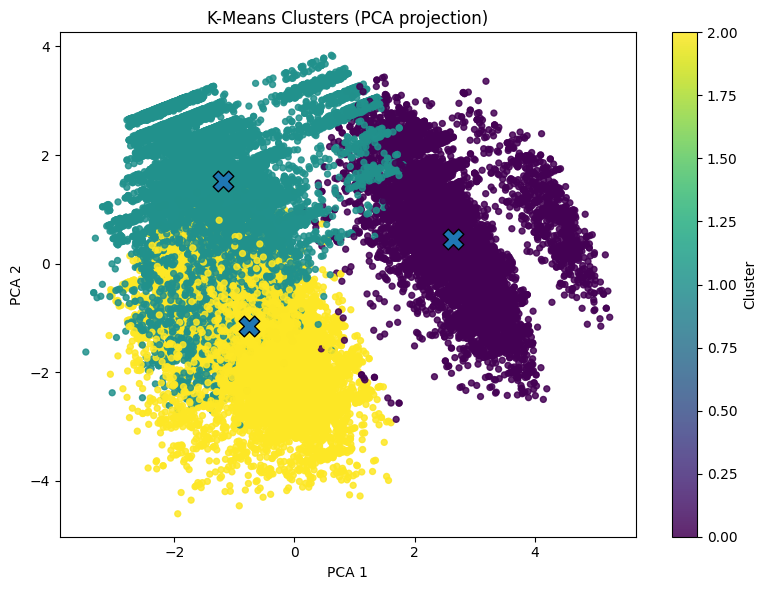

In [132]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1) Feature matrix (all numeric); drop rows with NaNs for PCA/KMeans
X = processed_dataset.select_dtypes(include=[np.number]).copy()

X = X.dropna()
idx = X.index  # remember which rows are used

# 2) Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3) K-Means
k = 3
km = KMeans(n_clusters=k, random_state=42, n_init=10)  # use n_init='auto' if your sklearn asks
y_pred = km.fit_predict(X_scaled)

# 4) Write/overwrite cluster labels directly into processed_dataset (no join => no overlap error)
processed_dataset.loc[idx, 'Group_cluster'] = y_pred

if 'age' in processed_dataset.columns:
    means = (
        processed_dataset.loc[idx]
        .groupby('Group_cluster')['age']
        .mean()
        .sort_values()
    )
    # map actual cluster ids -> rank 0/1/2 by mean age
    rank_map = {cluster_id: rank for rank, cluster_id in enumerate(means.index)}
    ranked = processed_dataset.loc[idx, 'Group_cluster'].map(rank_map)
    name_map = {0: 'Young', 1: 'Middle-aged', 2: 'Old'}
    processed_dataset.loc[idx, 'Label'] = ranked.map(name_map)

print("Cluster counts on clustered rows:")
print(processed_dataset.loc[idx, 'Group_cluster'].value_counts().sort_index())
if 'Label' in processed_dataset.columns:
    print("\nLabel counts:")
    print(processed_dataset.loc[idx, 'Label'].value_counts())

# 5) PCA -> 2D and plot
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(km.cluster_centers_)

plt.figure(figsize=(8,6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_pred, cmap='viridis', s=18, alpha=0.85)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='X', s=220, edgecolor='black', linewidth=1.0)
plt.title("K-Means Clusters (PCA projection)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
cbar = plt.colorbar(scatter)
cbar.set_label("Cluster")
plt.tight_layout()
plt.show()

Comparison analysis

In [ ]:
# Evaluation Function

def evaluate_model(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)


    r2 = r2_score(y_true, y_pred)
    return {
        'Model': name,

        'MSE/loss': round(mse,2),
        'R2 Score': round(r2,2)
    }

# Collect results
results = []
results.append(evaluate_model("Linear Regression", y_test, y_pred_lr))
results.append(evaluate_model("Decision Tree", y_test, y_pred_dt))
results.append(evaluate_model("Neural Network", y_test, y_pred_nn))

# Convert to DataFrame
results_df = pd.DataFrame(results)
print("\nModel Comparison:")
print(results_df)



Neural Network Epoch-wise training loss curve.

In [ ]:
def plot_nn_loss(nn_model):
    plt.plot(nn_model.loss_curve_, label="Training Loss")
    plt.title("Neural Network Loss Curve")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()


plot_nn_loss(nn_reg)

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
import numpy as np

def combined_loss_curves(lr, dt, nn, X_train, y_train):
    plt.figure(figsize=(10,6))

    # Linear Regression Learning Curve

    train_sizes, train_scores, val_scores = learning_curve(
        lr, X_train, y_train, cv=5, scoring='neg_mean_squared_error',
        train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
    )
    lr_val_loss = -np.mean(val_scores, axis=1)
    plt.plot(train_sizes, lr_val_loss, 'o-', label="Linear Regression (Val Loss)")

    # Decision Tree Learning Curve

    train_sizes, train_scores, val_scores = learning_curve(
        dt, X_train, y_train, cv=5, scoring='neg_mean_squared_error',
        train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
    )
    dt_val_loss = -np.mean(val_scores, axis=1)
    plt.plot(train_sizes, dt_val_loss, 's-', label="Decision Tree (Val Loss)")


    # Neural Network Loss Curve

    plt.plot(range(1, len(nn.loss_curve_)+1), nn.loss_curve_, '^-', label="Neural Network (Train Loss)")


    # Formatting

    plt.title("Loss Curves Comparison Across Models")
    plt.xlabel("Training Size / Epochs")
    plt.ylabel("Loss (MSE)")
    plt.legend()
    plt.grid(True)
    plt.show()
combined_loss_curves(lin_reg, dt_reg, nn_reg, X_train, y_train)
